In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('C:/data-analytics/unidad5/dia20/amz_uk_price_prediction_dataset.csv')
print(df.shape)
df.head()

(2443651, 9)


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


# PARTE1 : Analyzing Best-Seller Trends Across Product Categories
### 1.Crosstab Analysis:

In [3]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
crosstab_result['total'] = crosstab_result[False] + crosstab_result[True]
crosstab_result['bestseller_share %'] =(crosstab_result[True] / crosstab_result['total'])*100
crosstab_sorted = crosstab_result.sort_values('bestseller_share %', ascending=False)
crosstab_sorted.head(20)

isBestSeller,False,True,total,bestseller_share %
category,,,,
Grocery,9008,556,9564,5.813467
Smart Home Security & Lighting,98,6,104,5.769231
Health & Personal Care,9017,552,9569,5.768628
Mobile Phone Accessories,248,11,259,4.247104
Power & Hand Tools,8353,306,8659,3.533895
"Billiard, Snooker & Pool",241,8,249,3.212851
Pet Supplies,9152,285,9437,3.020028
Home Brewing & Wine Making,239,7,246,2.845528
Mirrors,243,7,250,2.800000


In [5]:
#las categorias donde hay mas bestsellers son : 'Grocery','Smart Home Security & Lighting','Health & Personal Care','Mobile Phone Accessories', algo para notar es que el 2do en el ranking tiene un total pequeño a comparacion al 1ro en el ranking

### 2.Pruebas estadisticas:

In [6]:
from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(50784.635515685426), np.float64(0.0))

In [13]:
from scipy.stats.contingency import association
tabla = pd.crosstab(df['category'], df['isBestSeller'])
association(tabla, method="cramer")

0.1222829439760564

### 3.Visualizaciones:

<Axes: xlabel='category'>

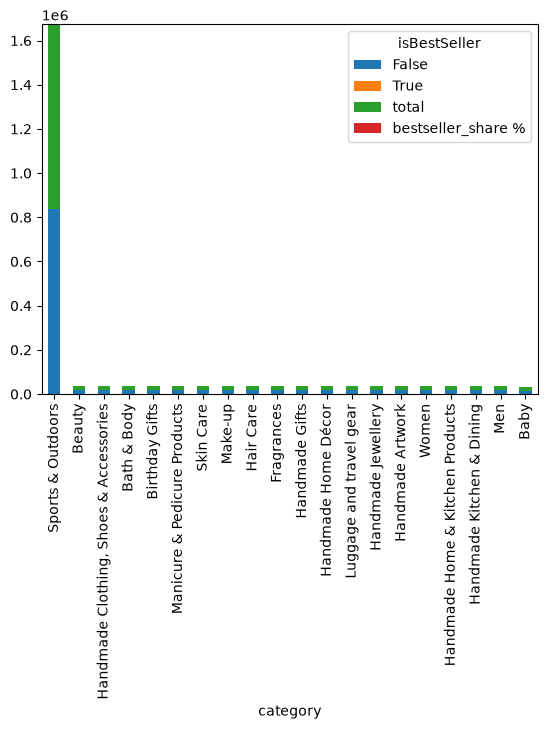

In [19]:
top20 = crosstab_result.sort_values("total", ascending=False).head(20)
top20.plot(kind="bar", stacked=True)

# PARTE2: Exploring Product Prices and Ratings Across Categories and Brands

In [21]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    
    return outliers

In [22]:
data_series = df['price']
outliers = tukeys_test_outliers(data_series)

In [24]:
print(f"Outliers encontrados: {len(outliers):,} ({len(outliers)/len(df):.1%} del total)")

Outliers encontrados: 327,688 (13.4% del total)


In [ ]:
df_clean_out = df.drop(outliers.index)

### 1.Tramas de violin:

In [56]:
top20_cats = df_clean_out["category"].value_counts().head(20).index
df_top20 = df_clean_out[df_clean_out["category"].isin(top20_cats)]


C:\Users\Usuario\AppData\Local\Temp\ipykernel_35240\3742029416.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data = df_top20, x="category", y="price", palette="coolwarm")


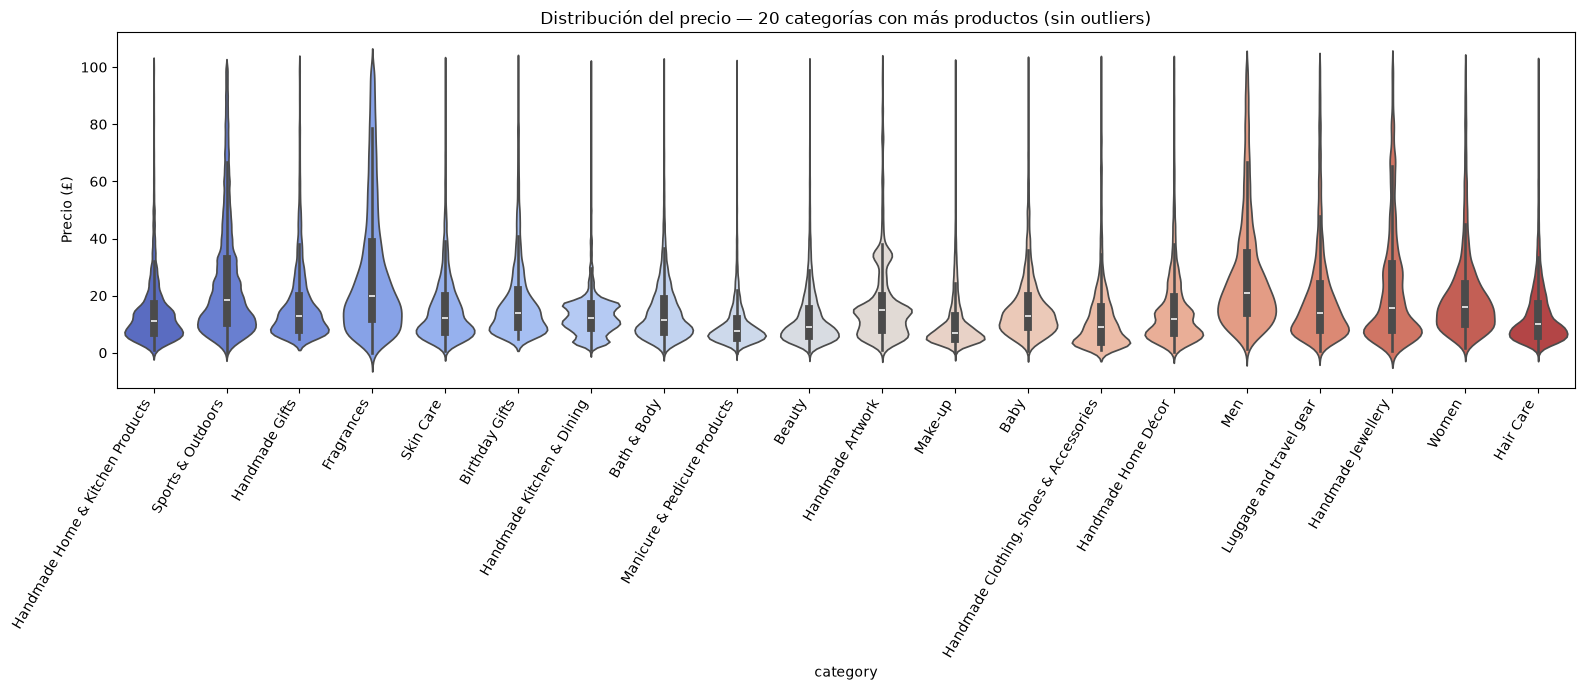

In [57]:
plt.figure(figsize=(16, 7))
sns.violinplot(data = df_top20, x="category", y="price", palette="coolwarm")
plt.xticks(rotation=60, ha="right")
plt.title("Distribución del precio — 20 categorías con más productos (sin outliers)")
plt.ylabel("Precio (£)")
plt.tight_layout()
plt.show()

In [52]:
media_precio = df_clean_out.groupby('category')['price'].mean().sort_values(ascending=False)
media_precio.head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

In [ ]:
#la categoria que tiene el precio promedio mas alto  es: Motherboards      68.772432

### 3.Diagramas de caja:

In [ ]:
top10_cats = df_clean_out["category"].value_counts().head(10).index
df_top10 = df_clean_out[df_clean_out["category"].isin(top10_cats)]

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
82168,89488,B07QDMLMJH,Nextbase Powered Mount Variations For Cameras ...,4.7,1223,19.95,False,0,Sports & Outdoors
82169,89489,B09TQMCNY7,WOLFANG Action Camera GA100 with 64GB microSDX...,4.2,55,49.99,False,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


C:\Users\Usuario\AppData\Local\Temp\ipykernel_35240\798722353.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm")


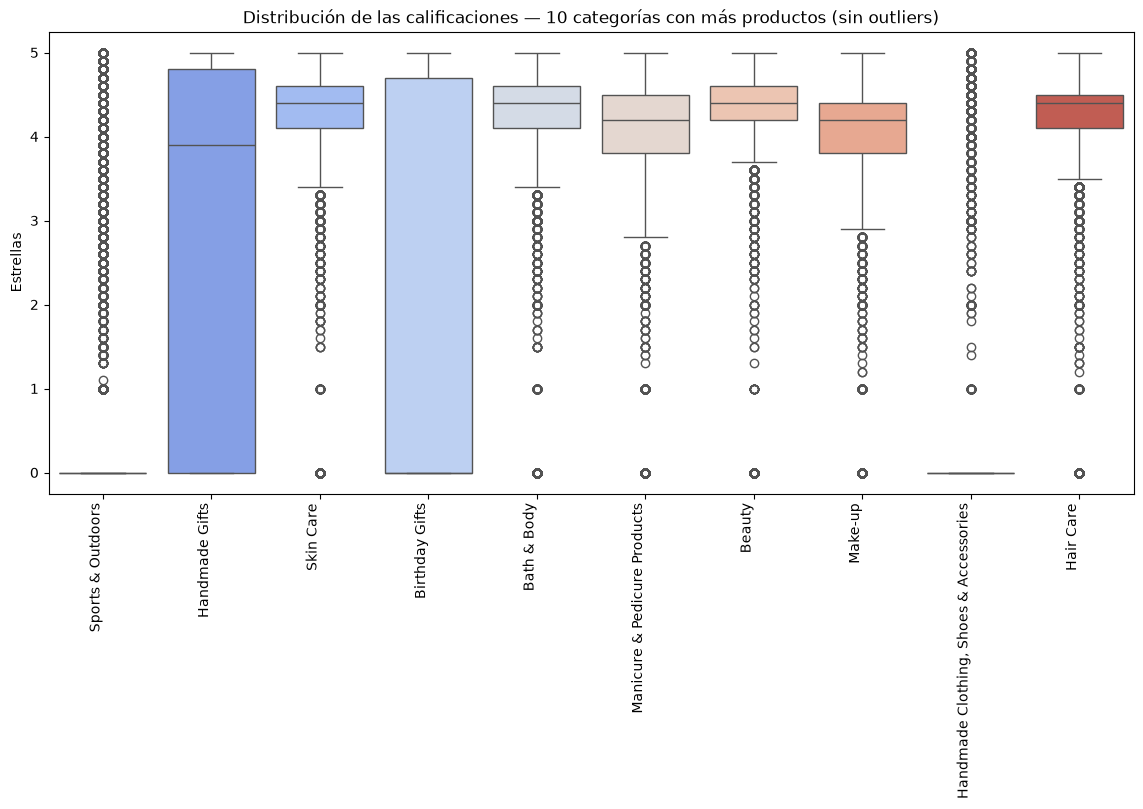

In [ ]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top10, x="category", y="stars", palette="coolwarm")
plt.xticks(rotation=90, ha="right")
plt.title("Distribución de las calificaciones — 10 categorías con más productos (sin outliers)")
plt.xlabel("")
plt.ylabel("Estrellas")
plt.show()

In [68]:
media_stars = (df_clean_out.groupby("category")["stars"].median().sort_values(ascending=False))
media_stars.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

In [ ]:
# la categoria en recibir mejor puntuacion es la de: 'computer memory'


# PARTE 3 :Investigación de la interacción entre precios y valoraciones de productos
### 1.Coeficientes de correlacion:

In [ ]:
pearson = df_clean_out['price'].corr(df_clean_out['stars'])
spearman = df_clean_out['price'].corr(df_clean_out['stars'], method='spearman')

print(f'pearson: {pearson}')
print(f'spearman: {spearman}')


pearson: -0.07767299878178476
spearman: -0.06679697280756669


In [ ]:
# La correlacion entre el precio y la calificacion es negativa y muy debil ya que esta muy proxima al 0(Pearson = -0,078; Spearman = -0,067)


### 2.Visualizaciones:

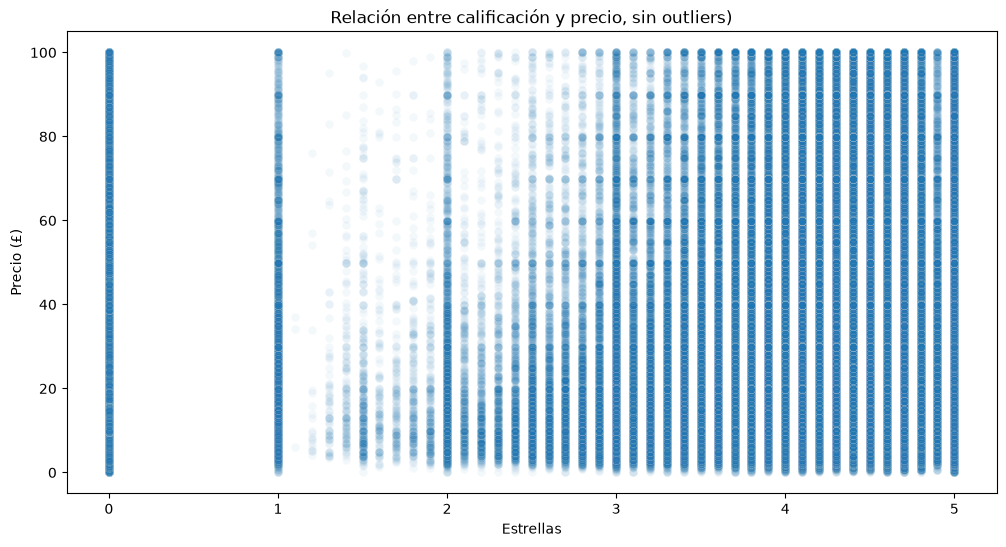

In [74]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=df_clean_out, x='stars', y='price', alpha=0.05)
plt.title("Relación entre calificación y precio, sin outliers)")
plt.xlabel("Estrellas")
plt.ylabel("Precio (£)")
plt.show()

In [ ]:
# use el parametro alpha, porque no se lograba apreciar muy bien el grafico, debido a que las estrellas son valores discretos
# EN el diagrama de dispersion no  se muestra alguna relacoin entre precio y calificaciones, las calificaciones entre 1 y 2 estrellas son poco frecuentes y existe un grupo grande de productos sin valoraciones(0 estrellas)

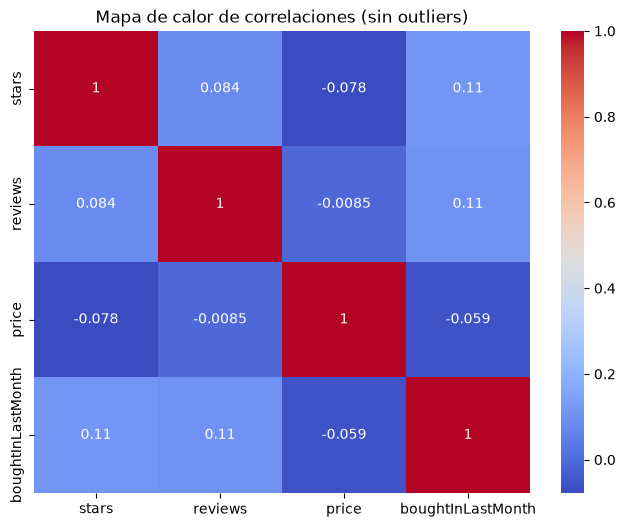

In [79]:
c_numericas = df_clean_out.select_dtypes(include="number").drop(columns=["uid"])
matriz_cor = c_numericas.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_cor, annot=True, cmap="coolwarm")
plt.title("Mapa de calor de correlaciones (sin outliers)")
plt.show()

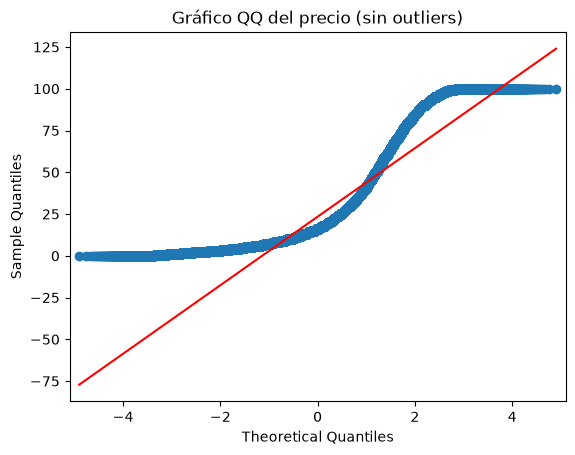

In [81]:
import statsmodels.api as sm
sm.qqplot(df_clean_out['price'], line='s')
plt.title("Gráfico QQ del precio (sin outliers)")
plt.show()

In [ ]:
# Los precios siguen una distribucion en forma de “S”, con precios concentrados en valores bajos, un mínimo en 0 y un corte en unos 100 £ debido PRUEBA ERRORES CONFLICTO
PRUEBA ERRORES CONFLICTO

In [ ]:
# PRUEBA DE ERRORES CONCLICTO